# 3. Political Maps

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
from shapely.geometry import box
from matplotlib_map_utils import north_arrow, scale_bar, inset_map

In [2]:
gpkg_path = Path('../data/outputs/netherlands.gpkg')
export_path = Path('../data/outputs/netherlands_provinces.png')

country = gpd.read_file(gpkg_path, layer='country')

provinces = gpd.read_file(gpkg_path, layer='provinces')
overijssel = provinces[
    provinces['name']=='Overijssel'
]

cities = gpd.read_file(gpkg_path, layer='cities')
enschede = cities[
    cities['name']=='Enschede'
]

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

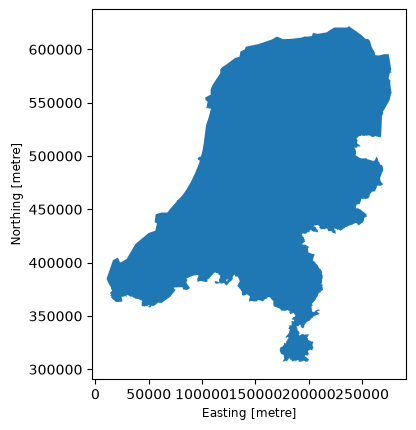

In [3]:
country.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

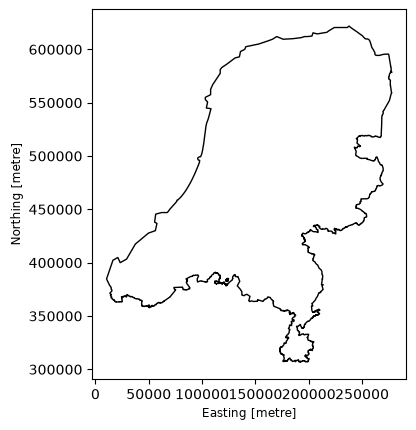

In [4]:
country.plot(color='none')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

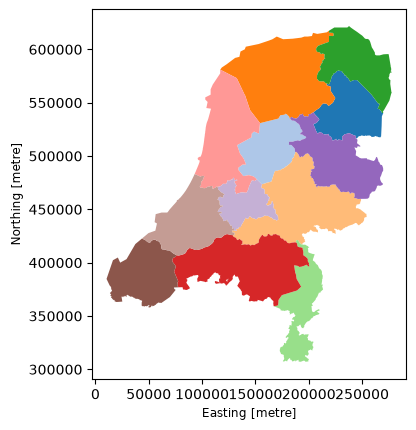

In [5]:
provinces.plot(column='name')

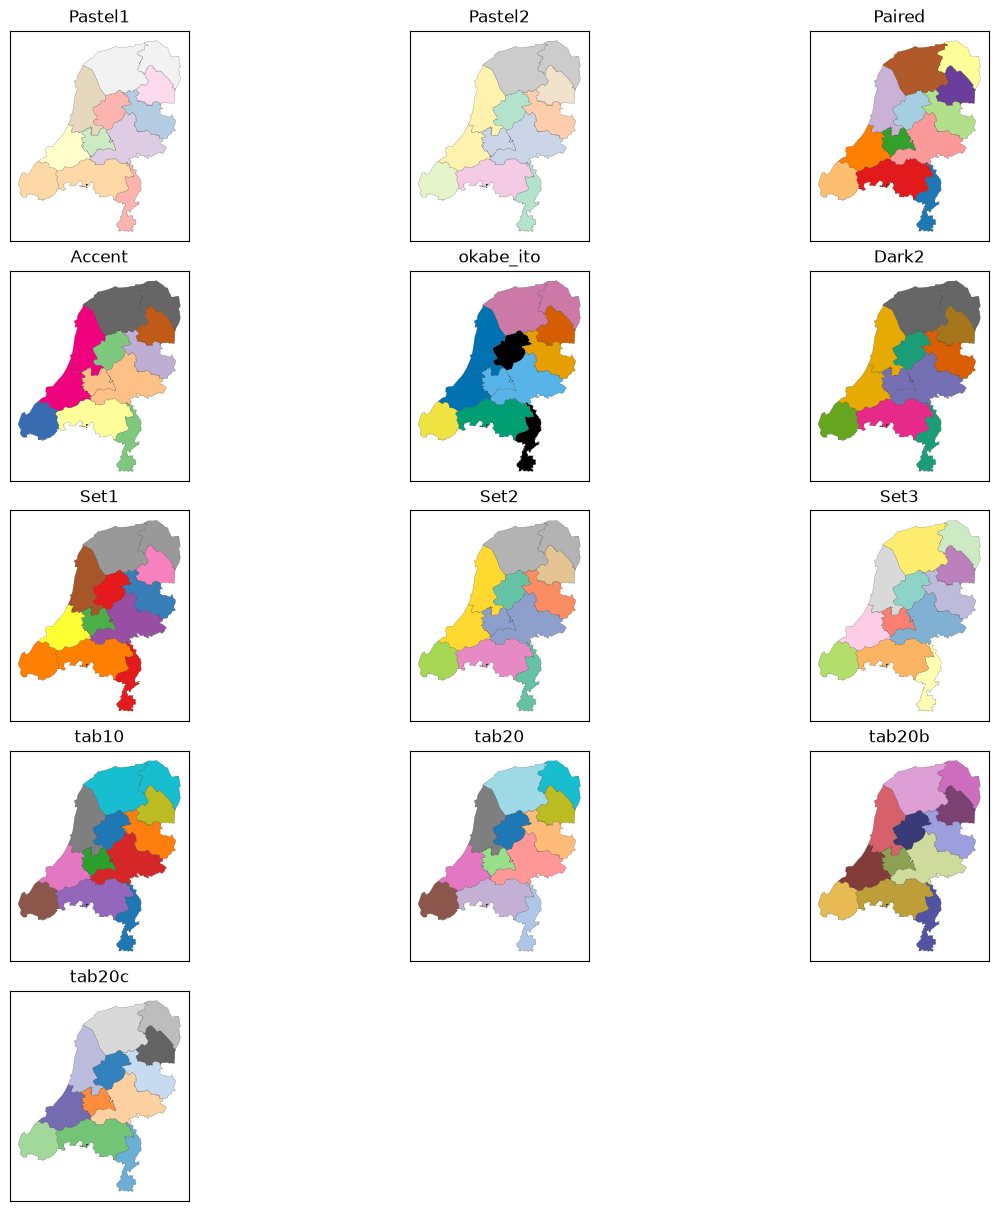

In [6]:
cmaps = ['Pastel1', 'Pastel2', 'Paired', 'Accent', 'okabe_ito',
        'Dark2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20',
        'tab20b', 'tab20c']

fig, axes = plt.subplots(
    5, 3,
    figsize=(12,12),
    constrained_layout=True
)

axes = axes.flatten()

for ax, cmap in zip(axes, cmaps):
    provinces.plot(
        ax=ax,
        cmap=cmap,
        edgecolor='black',
        linewidth=0.1
    )

    ax.set(
        title=cmap,
        xlabel='',
        ylabel='',
        xticks=[],
        yticks=[]
    )

for ax in axes[len(cmaps): ]:
    ax.remove()
    
plt.show()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

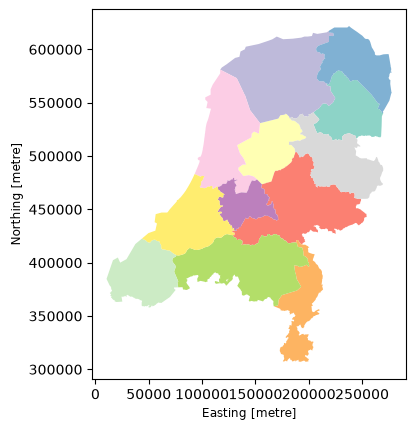

In [7]:
provinces.plot(
    column='name',
    cmap='Set3'
)

In [8]:
enschede.explore()

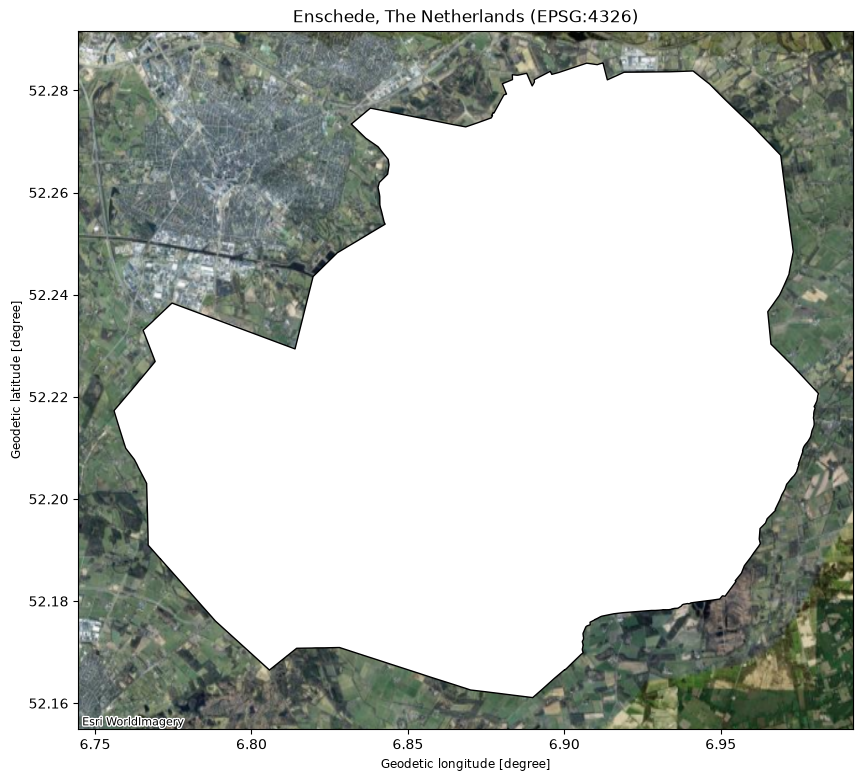

In [9]:
fig, ax = plt.subplots(figsize=(10,10))

enschede = enschede.to_crs('EPSG:4326')

enschede.plot(
    ax=ax,
    color='white',
    edgecolor='black',
    linewidth=1
)

cx.add_basemap(
    ax=ax,
    crs=enschede.crs,
    source=cx.providers.Esri.WorldImagery,
    attribution='Esri WorldImagery'
)

ax.set(
    title=f'Enschede, The Netherlands ({enschede.crs})'
)

plt.show()

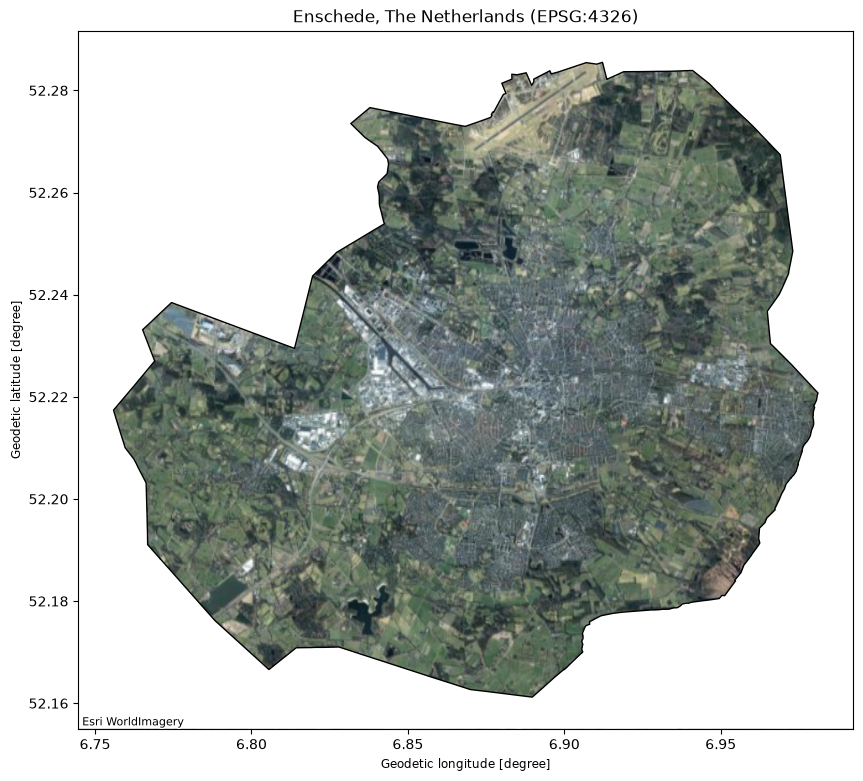

In [10]:
fig, ax = plt.subplots(figsize=(10,10))

enschede.plot(
    ax=ax,
    alpha=0
)

cx.add_basemap(
    ax,
    crs=enschede.crs,
    source=cx.providers.Esri.WorldImagery,
    attribution='Esri WorldImagery'
)

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

plot_box = box(xmin, ymin, xmax, ymax)
inverse_mask = plot_box.difference(enschede.geometry)

inverse_mask.plot(
    ax=ax,
    color='white'
)

enschede.plot(
    ax=ax,
    color='none',
    edgecolor='black',
    linewidth=1
)

ax.set(
    title=f'Enschede, The Netherlands ({enschede.crs})'
)


plt.show()

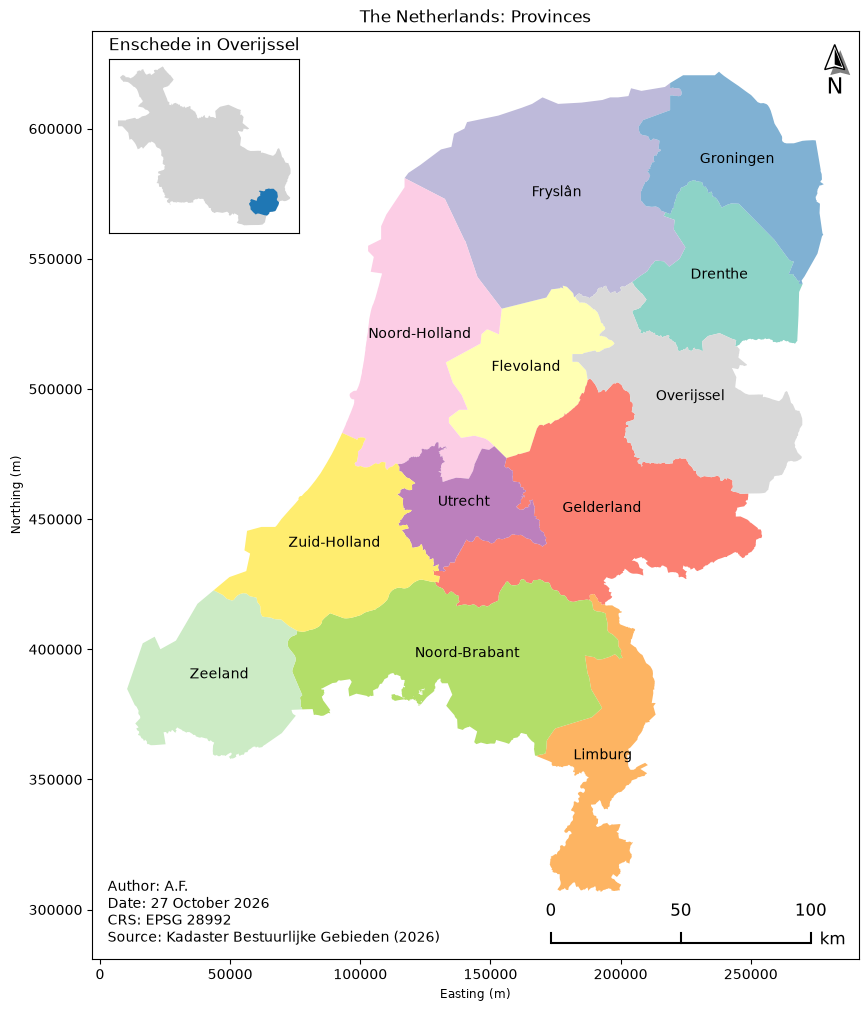

In [11]:
enschede = enschede.to_crs('EPSG:28992')

fig, ax = plt.subplots(
    figsize=(10,10),
    constrained_layout=True
)

provinces.plot(
    ax=ax,
    column='name',
    categorical=True,
    cmap='Set3'
)

for row in provinces.itertuples():
    centroid = row.geometry.centroid

    ax.annotate(
        row.name,
        xy=(centroid.x, centroid.y),
        ha='center'
    )

ymin, ymax = ax.get_ylim()

ax.set(
    title='The Netherlands: Provinces',
    xlabel='Easting (m)',
    ylabel='Northing (m)',
    ylim=(ymin - 10000, ymax)
)

north_arrow(
    ax,
    location='upper right',
    scale=0.25
)

scale_bar(
    ax,
    location='lower right',
    style='ticks',
    bar={
        'projection':provinces.crs,
        'length':2.85
    }
)

inset = inset_map(
    ax,
    coords=(0.27, 0.97),
)

overijssel.plot(
    ax=inset,
    color='lightgrey'
)

enschede.plot(
    ax=inset
)

inset.set(
    title='Enschede in Overijssel',
    xlabel='',
    ylabel='',
    xticks=[],
    yticks=[]
)

ax.text(
    x=0.02,
    y=0.05,
    s='Author: A.F.\n'
    'Date: 27 October 2026\n'
    'CRS: EPSG 28992\n'
    'Source: Kadaster Bestuurlijke Gebieden (2026)',
    va='center',
    transform=ax.transAxes
)

plt.savefig(export_path, dpi=300, bbox_inches='tight')
plt.show()